# Fig. 2 — Leader–follower dynamics across the four game regimes
Leader fraction $x(t)$ (top) and $\log_{10} N(t)$ (bottom) for the growth-coupled model, $N(0)=10^5$, $K=10^{10}$,
initial leader fractions $x_0 = 0.1, \dots, 0.9$, α = 0.4, δ = 0.6.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lf_model import *
set_style()

In [2]:
x0s = np.array([0.1, 0.3, 0.5, 0.7, 0.9])
colors = ["#b2182b", "#ef8a62", "#cccccc", "#67a9cf", "#2166ac"]
T = 30.0
res = {}
for name, (b, g) in REGIMES.items():
    res[name] = simulate(ALPHA, b, g, DELTA, x0=x0s, T=T, dt=0.01, return_traj=True, n_save=600)

# numbers quoted in the text: N(15)/K for x0 = 0.5
for name, (b, g) in REGIMES.items():
    _, n15 = simulate(ALPHA, b, g, DELTA, x0=0.5, T=15)
    print(f"{name:20s} N(15)/K = {100 * n15 / K:.2f}%   x* = {interior_equilibrium(ALPHA, b, g, DELTA):.2f}")

Snowdrift            N(15)/K = 17.24%   x* = 0.33
Harmony              N(15)/K = 0.76%   x* = nan
Coordination         N(15)/K = 1.04%   x* = 0.67
Prisoner's Dilemma   N(15)/K = 5.43%   x* = nan


Saved ../figures/Fig2_dynamics_four_game_regimes.png/.pdf


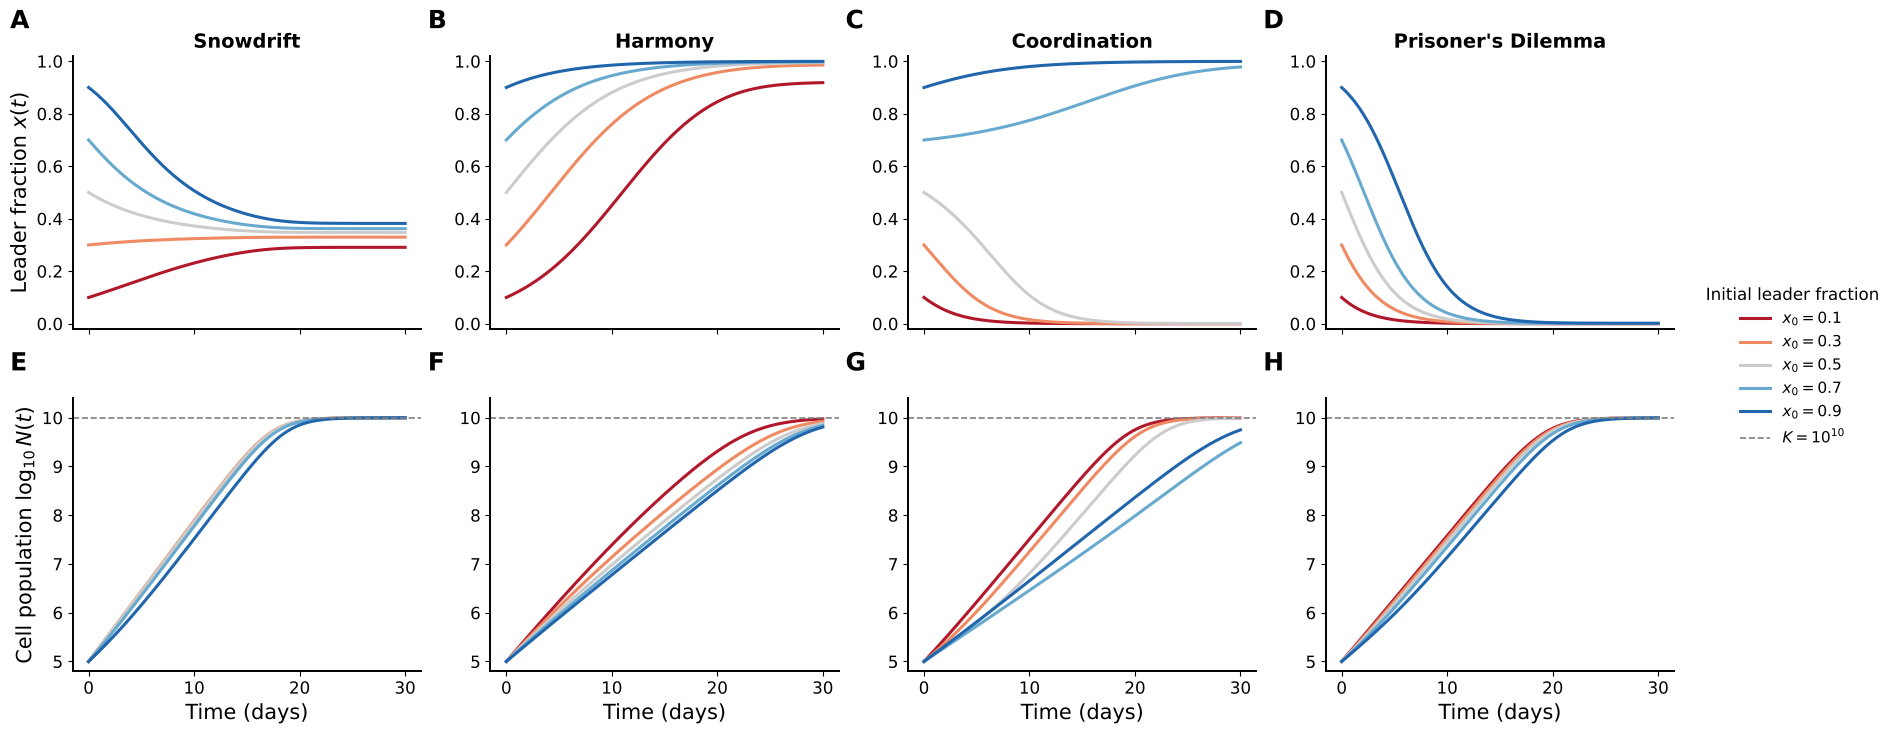

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharex=True)
for j, name in enumerate(REGIME_ORDER):
    _, _, t, xs, ns = res[name]
    for k, x0 in enumerate(x0s):
        axes[0, j].plot(t, xs[:, k], color=colors[k], lw=2.2, label=f"$x_0={x0}$")
        axes[1, j].plot(t, np.log10(ns[:, k]), color=colors[k], lw=2.2)
    axes[1, j].axhline(np.log10(K), color="gray", ls="--", lw=1.2, label=r"$K=10^{10}$")
    axes[0, j].set_title(name, fontweight="bold")
    axes[0, j].set_ylim(-0.02, 1.02)
    axes[1, j].set_ylim(4.8, 10.4)
    axes[1, j].set_xlabel("Time (days)")
    panel_letter(axes[0, j], "ABCD"[j]); panel_letter(axes[1, j], "EFGH"[j])
axes[0, 0].set_ylabel("Leader fraction $x(t)$")
axes[1, 0].set_ylabel(r"Cell population $\log_{10} N(t)$")
h1, l1 = axes[0, 0].get_legend_handles_labels()
h2, l2 = axes[1, 0].get_legend_handles_labels()
fig.legend(h1 + h2[-1:], l1 + l2[-1:], title="Initial leader fraction", loc="center left",
           bbox_to_anchor=(1.0, 0.5), frameon=False)
fig.tight_layout()
save(fig, "Fig2_dynamics_four_game_regimes")
plt.show()